In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import pandas as pd

file_path = "/kaggle/input/datasets/ramanipkg/linearstudentdata/Linear_Regression_FDP_Student_Dataset.xlsx"

df = pd.read_excel(file_path)

print(df.head())

   Student_ID  Study_Hours  Attendance_Percent  Previous_Marks  \
0        1001          1.0                  65              38   
1        1002          2.0                  70              42   
2        1003          3.0                  72              48   
3        1004          4.0                  75              50   
4        1005          5.0                  78              55   

   Assignment_Score  Exam_Marks  
0                40          35  
1                45          40  
2                50          46  
3                55          52  
4                58          57  


In [8]:
df.tail()

,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
25,1026,8.0,88,69,73,76
26,1027,9.0,91,74,79,83
27,1028,3.5,75,50,53,51
28,1029,6.5,87,66,68,69
29,1030,8.5,90,71,76,79


In [9]:
print("Dataset Shape:", df.shape)

Dataset Shape: (30, 6)


In [10]:
print(df.columns)

Index(['Student_ID', 'Study_Hours', 'Attendance_Percent', 'Previous_Marks',
       'Assignment_Score', 'Exam_Marks'],
      dtype='object')


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_ID          30 non-null     int64  
 1   Study_Hours         30 non-null     float64
 2   Attendance_Percent  30 non-null     int64  
 3   Previous_Marks      30 non-null     int64  
 4   Assignment_Score    30 non-null     int64  
 5   Exam_Marks          30 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 1.5 KB


In [12]:
df.describe()

,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,1015.500000,5.566667,80.666667,57.933333,61.800000,61.333333
std,8.803408,2.615383,7.778544,11.343944,12.338334,15.173328
min,1001.000000,1.000000,65.000000,38.000000,40.000000,35.000000
25%,1008.250000,3.500000,75.000000,49.250000,52.250000,49.500000
50%,1015.500000,5.750000,80.500000,57.500000,61.000000,61.000000
75%,1022.750000,7.875000,86.750000,67.500000,71.500000,72.500000
max,1030.000000,10.000000,95.000000,78.000000,85.000000,90.000000


In [13]:
print(df.isnull().sum())

Student_ID            0
Study_Hours           0
Attendance_Percent    0
Previous_Marks        0
Assignment_Score      0
Exam_Marks            0
dtype: int64


In [14]:
df = df.dropna()

print("Missing values handled")

Missing values handled


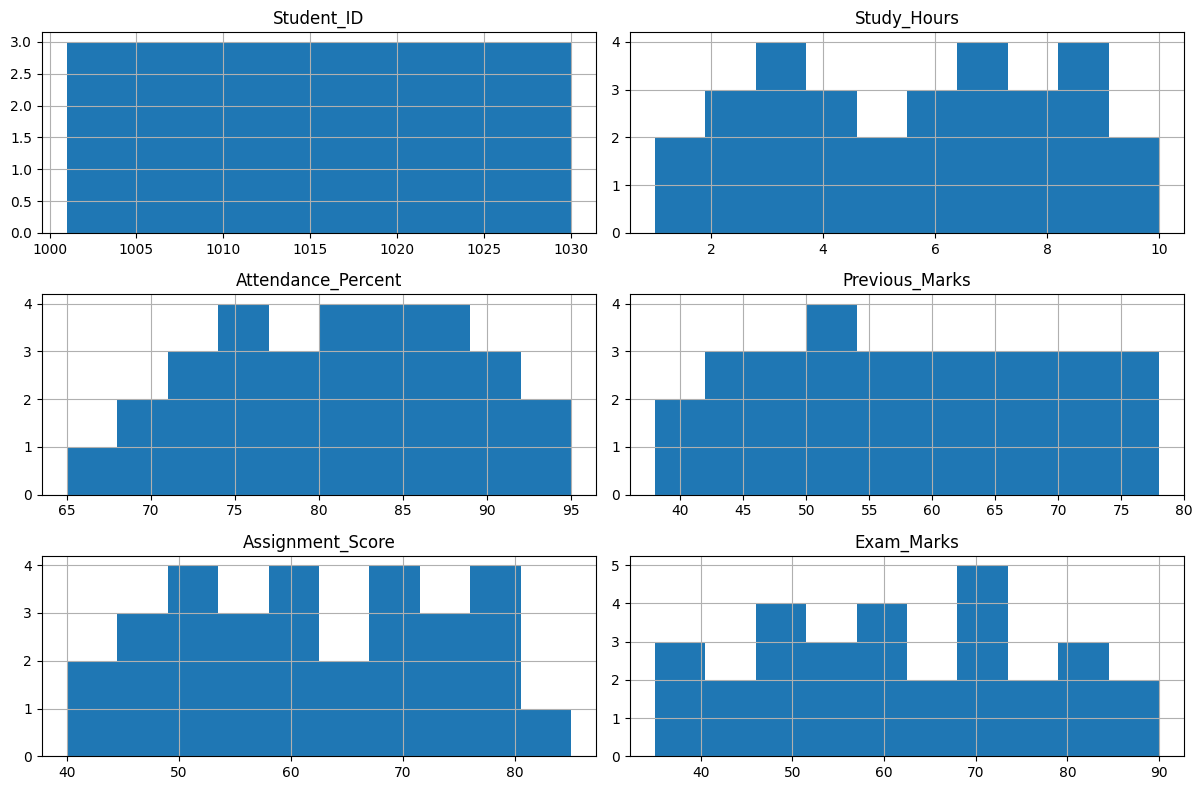

In [15]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

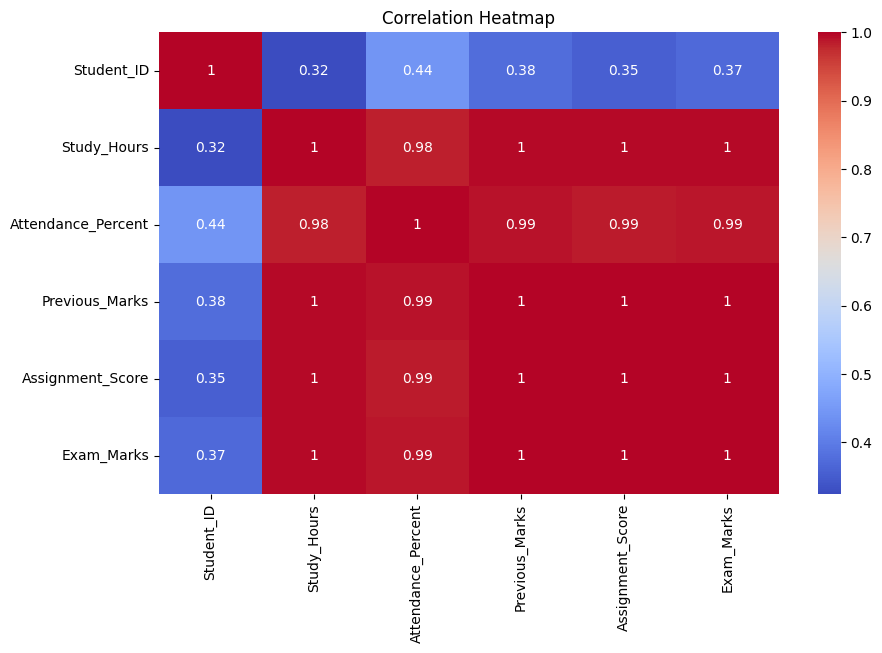

In [16]:
plt.figure(figsize=(10, 6))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [17]:
print(df.columns.tolist())

['Student_ID', 'Study_Hours', 'Attendance_Percent', 'Previous_Marks', 'Assignment_Score', 'Exam_Marks']


In [20]:
X = df[['Study_Hours']]
y = df['Exam_Marks']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 1)
Testing data: (6, 1)


In [22]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [23]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

Predicted Values:
[49.37621682 66.69045451 63.80474823 78.23327964 81.11898592 86.89039849]


In [24]:
result = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_pred
})

print(result)

   Actual Values  Predicted Values
0             51         49.376217
1             65         66.690455
2             64         63.804748
3             77         78.233280
4             80         81.118986
5             90         86.890398


In [25]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 1.4952260895954446


In [26]:
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 2.9958602106124643


In [27]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 1.7308553407527922


In [28]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.9813309732418126


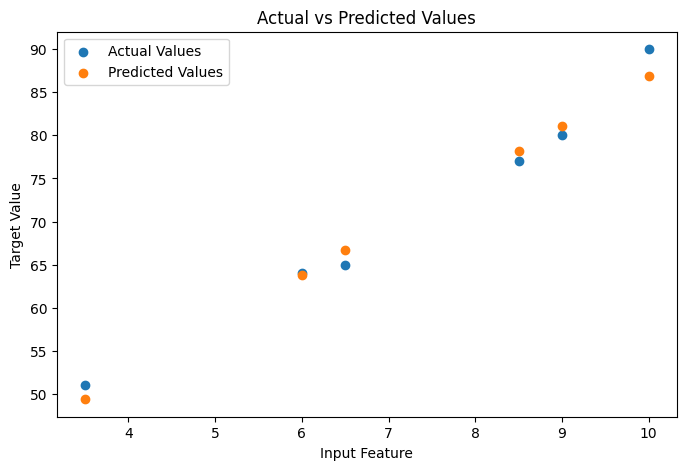

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test.iloc[:, 0], y_test,
            label="Actual Values")

plt.scatter(X_test.iloc[:, 0], y_pred,
            label="Predicted Values")

plt.xlabel("Input Feature")
plt.ylabel("Target Value")
plt.title("Actual vs Predicted Values")

plt.legend()
plt.show()

In [30]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_)

Intercept: 29.176272848238675
Coefficient: [5.77141256]


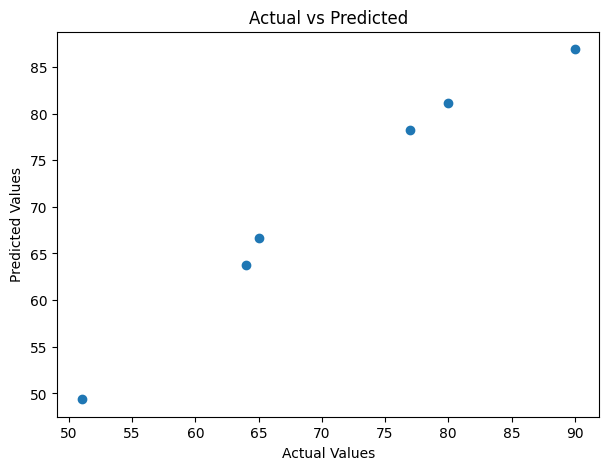

In [31]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")

plt.show()